# Test opponent-map display conversion
Set the HDF5 path and frame index below, then run all cells. Only the selected frame's normalization window is loaded. The plots compare the original signed channel values with the uint8 display values; these are not natural RGB colors.

Uses Geoff's [rolling-window instructions](https://upennvisionlabs.slack.com/archives/C08D870F54P/p1793712750563809).

In [1]:
from pathlib import Path
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / "code/library/sensor_utility/world_util.py").exists())
sys.path.insert(0, str(project_root / "code/library/sensor_utility"))
import world_util
import sensors_utility

In [3]:
hdf5_path = Path("/Volumes/FLIC_processing/NEWscriptedIndoorOutdoorVideos2026/FLIC_20/walkOutdoor/GKA/1/W/transformed.hdf5")
raw_chunks_path = Path("/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVideos2026/FLIC_20/walkOutdoor/GKA/1")  # Set the directory containing world and MS chunks.
frame_index = 5836  # Verified L+M coverage in this recording.
fps = 120.0  # Recording and playback rate (frames per second)
window_seconds = 1.0


Loading world chunks:   0%|          | 0/47 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

... (38 outputs left out)

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/689 [00:00<?, ?it/s]

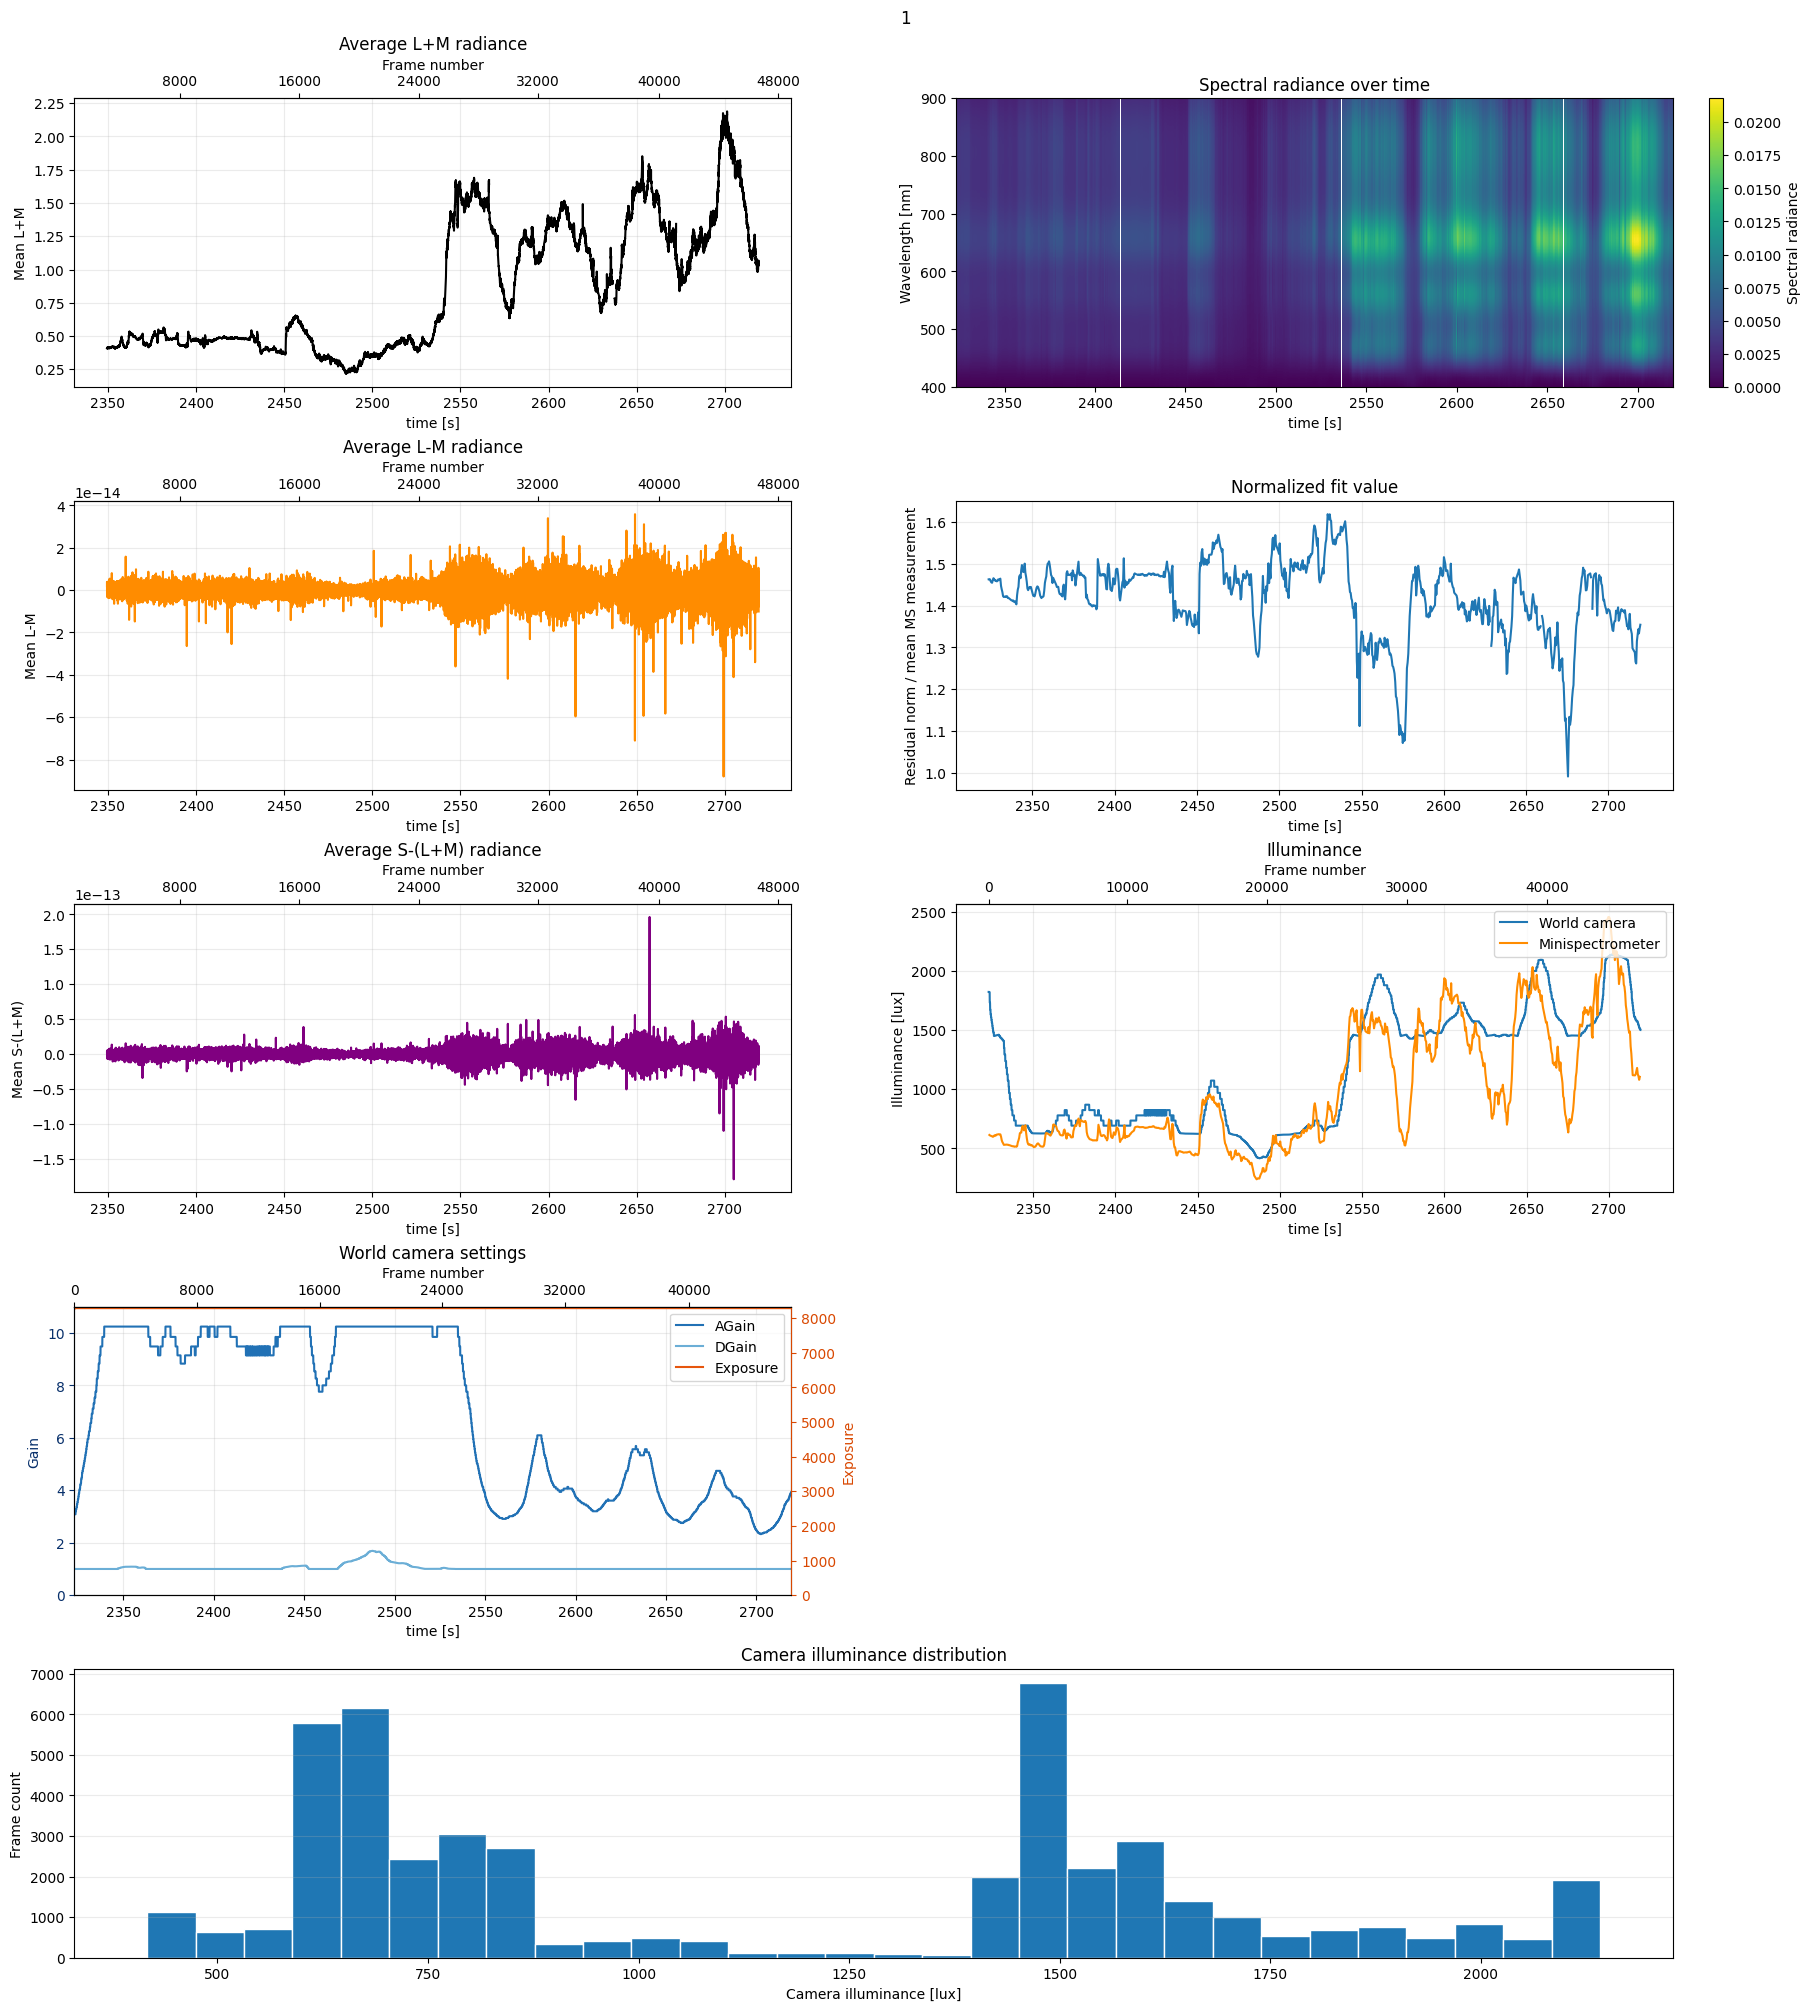

In [4]:


# The world file lives in W; its parent recording also contains M.
recording_directory = hdf5_path.expanduser().parent.parent
recording_figure, recording_axes = sensors_utility.plot_processed_recording(
    str(recording_directory), verbose=True
)
plt.show()


In [ ]:
# Plot the raw world and MS chunks with progress reporting.
raw_figure, raw_axes = sensors_utility.plot_raw_recording(
    str(raw_chunks_path.expanduser()), verbose=True
)
plt.show()


In [ ]:
with h5py.File(hdf5_path.expanduser(), "r") as saved:
    frames = saved["data/frames"]
    assert 0 <= frame_index < len(frames), "frame_index is outside the recording."
    window_frames = min(len(frames), max(1, int(round(fps * window_seconds))))
    start = min(max(frame_index - window_frames // 2, 0), len(frames) - window_frames)
    opponentmaps = frames[start:start + window_frames]

converted_frames = world_util.opponentmap_to_videoframe(
    opponentmaps, fps=fps, window_seconds=window_seconds
)
selected = frame_index - start
before = opponentmaps[selected]
after = converted_frames[selected]
print(f"Loaded frames {start}:{start + window_frames}; output {converted_frames.shape}, {converted_frames.dtype}")


In [ ]:
fig = world_util.plot_opponent_frame_conversion(before, after)
plt.show()


In [ ]:
# Export the recording as an L+M video with the visual-angle overlay.
sys.path.insert(0, str(project_root / "code/library/matlabIO/python_libraries"))
import video_io

output_path = Path.home() / "Desktop" / "opponentmap_lm_test.avi"
video_io.opponentmaps_to_video(
    str(hdf5_path), str(output_path),
    fill_missing_frames=True, verbose=True, overlay=True,
)
print(output_path)

In [ ]:
# Export plotted data for illuminance/video comparison.
recording_figure.savefig('/tmp/illuminance_latest.png', dpi=120)
np.savez('/tmp/illuminance_series.npz', camera_time=recording_axes[2, 1].lines[0].get_xdata(), camera_lux=recording_axes[2, 1].lines[0].get_ydata(), ms_time=recording_axes[2, 1].lines[1].get_xdata(), ms_lux=recording_axes[2, 1].lines[1].get_ydata())
print('Exported plot and illuminance series.')

In [ ]:
# Reprocess the illuminance dips one at a time, then save each processed plot
# and an L+M GIF with the full plot below it and synchronized red time bars.
# W/M HDF5 files and the temporary AVI are overwritten on the next iteration;
# numbered PNGs and GIFs are retained. Run this cell after the imports/path cells.
import importlib
import cv2
from PIL import Image, ImageDraw
from IPython.display import display

sys.path.insert(0, str(project_root / "code/preprocessRecordingData"))
sys.path.insert(0, str(project_root / "code/library/matlabIO/python_libraries"))
import chunk_io
import video_io
import preprocessing_pipeline
importlib.reload(world_util)
importlib.reload(sensors_utility)
importlib.reload(video_io)

# These are absolute recording-clock seconds, matching the illuminance plot.
dip_starts: tuple[float, ...] = (2566., 2624., 2665., 2708.)
dip_ends: tuple[float, ...] = (2585., 2645., 2686., 2719.)
context_seconds: float = 40.
gif_fps: int = 5
assert len(dip_starts) == len(dip_ends), "Each dip needs a start and end time."

recording_directory: Path = hdf5_path.expanduser().parent.parent
dip_work_directory: Path = recording_directory / "dip_work"
dip_export_directory: Path = Path.home() / "Desktop" / "illuminance_dips_regenerated"
dip_export_directory.mkdir(parents=True, exist_ok=True)
dip_work_directory.mkdir(parents=True, exist_ok=True)

# Match the participant age and gaze alignment used by the main pipeline.
subject_id: int = int(raw_chunks_path.parents[2].name.split("_")[-1])
subject_age: int = preprocessing_pipeline.get_subject_ids()[subject_id]
mapper_directory: Path = recording_directory.parents[1] / "Neon" / raw_chunks_path.name / "egocentric_mapper_results"
neon_directory: Path = raw_chunks_path.parents[1] / "Neon" / raw_chunks_path.name / "timeseries_and_video_export"
gaze_angles_xy: np.ndarray = preprocessing_pipeline._align_gaze_to_raw_world_frames(
    str(raw_chunks_path), str(mapper_directory), str(neon_directory),
)

# Establish each sensor's own time origin; chunk lookup expects relative seconds.
sensor_files: dict = chunk_io.group_sensors_files(str(raw_chunks_path))
sensor_times: dict[str, np.ndarray] = {}
sensor_native_times: dict[str, np.ndarray] = {}
for sensor in ("W", "M"):
    time_chunks: list[np.ndarray] = []
    for metadata_path, _ in sensor_files[sensor]:
        metadata = np.load(metadata_path, mmap_mode="r")
        if len(metadata):
            time_chunks.append(np.asarray(metadata if metadata.ndim == 1 else metadata[:, 0], dtype=float))
    assert time_chunks, f"No timestamps found for {sensor}."
    sensor_native_times[sensor] = np.concatenate(time_chunks)
    sensor_times[sensor] = sensor_native_times[sensor] / (1e9 if sensor == "W" else 1)
    assert np.all(np.diff(sensor_times[sensor]) > 0), f"{sensor} timestamps must increase."

# Keep the illuminance scale identical to the previously reviewed full plot.
illuminance_limits: tuple[float, float] = (127.55373085743565, 2569.3473136212237)

for dip_number, (start, end) in enumerate(zip(dip_starts, dip_ends), start=1):
    assert start < end, f"Invalid dip interval: {start}, {end}."
    assert sensor_times["W"][0] <= start < end <= sensor_times["W"][-1], "Dip is outside the world recording."
    plot_start: float = start - context_seconds
    plot_end: float = end + context_seconds
    chunk_ranges: dict[str, tuple[int, int]] = {}

    # Include context in the processed chunks, but animate only the dip interval.
    # Snap lookup edges outward to stored samples so edges in gaps remain valid.
    for sensor in ("W", "M"):
        times = sensor_times[sensor]
        first_index: int = max(0, int(np.searchsorted(times, plot_start, side="right")) - 1)
        last_index: int = min(len(times) - 1, int(np.searchsorted(times, plot_end, side="left")))
        native_times = sensor_native_times[sensor]
        unit_scale: float = 1e9 if sensor == "W" else 1
        relative_range = (
            float((native_times[first_index] - native_times[0]) / unit_scale),
            float((native_times[last_index] - native_times[0]) / unit_scale),
        )
        selected = chunk_io.find_chunks_by_timestamp(str(raw_chunks_path), sensor, relative_range)
        assert all(index is not None for index in selected), f"No {sensor} chunks for {relative_range}: {selected}"
        chunk_ranges[sensor] = selected

    print(f"Dip {dip_number}: {start:g}–{end:g} s; chunk ranges {chunk_ranges}", flush=True)
    sensors_utility.process_raw_recording(
        path_to_raw=raw_chunks_path, output_path=dip_work_directory,
        age=subject_age, gaze_angles_xy=gaze_angles_xy,
        chunk_ranges=chunk_ranges, overwrite_existing=True, verbose=True,
    )

    # Plot the new spectra, channel means, AGC, illuminance and raw pixel counts.
    dip_figure, dip_axes = sensors_utility.plot_processed_recording(
        dip_work_directory, verbose=True, plot_title=f"Dip {dip_number}: {start:g}–{end:g} s",
    )
    for axis in dip_axes.flat:
        axis.set_xlim(plot_start, plot_end)
    dip_axes[2, 1].set_ylim(*illuminance_limits)
    dip_axes[2, 1].set_yticks([500, 1000, 1500, 2000, 2500])
    stem: str = f"dip_{dip_number}_{start:g}-{end:g}s"
    dip_figure.savefig(dip_export_directory / f"{stem}.png", dpi=150)
    display(dip_figure)

    # Render a temporary video from this iteration's newly processed world maps.
    world_file: Path = dip_work_directory / "W" / "transformed.hdf5"
    video_path: Path = dip_work_directory / "dip_video.avi"
    video_io.opponentmaps_to_video(
        str(world_file), str(video_path), fill_missing_frames=True, verbose=True, overlay=True,
    )
    video_times: np.ndarray = world_util.world_metadata_from_chunks(
        str(world_file), fill_missing_frames=True,
    )["timestamp"].to_numpy()

    # Cache the entire processed plot and its axis bounds, then draw only cursors.
    dip_figure.set_dpi(60)
    dip_figure.canvas.draw()
    plot_image = Image.fromarray(np.asarray(dip_figure.canvas.buffer_rgba())[:, :, :3].copy())
    panel_bounds = [axis.get_window_extent().bounds for axis in dip_axes.flat]
    video_height: int = 400
    header_height: int = 30
    plot_offset: int = video_height + header_height
    gif_frames: list[Image.Image] = []
    capture = cv2.VideoCapture(str(video_path))
    try:
        assert capture.isOpened(), f"Cannot open {video_path}."
        assert int(capture.get(cv2.CAP_PROP_FRAME_COUNT)) == len(video_times), "Video and timestamp lengths differ."
        for timestamp in np.arange(start, end, 1 / gif_fps):
            # Use the writer's filled timeline, preserving the timing of camera gaps.
            video_index: int = int(np.argmin(np.abs(video_times - timestamp)))
            capture.set(cv2.CAP_PROP_POS_FRAMES, video_index)
            success, video_frame = capture.read()
            assert success, f"Cannot read video frame {video_index}."
            canvas = Image.new("RGB", (plot_image.width, plot_offset + plot_image.height), "white")
            preview = Image.fromarray(cv2.cvtColor(video_frame, cv2.COLOR_BGR2RGB)).resize((400, 400))
            canvas.paste(preview, ((plot_image.width - 400) // 2, header_height))
            canvas.paste(plot_image, (0, plot_offset))
            draw = ImageDraw.Draw(canvas)
            draw.text((12, 8), f"Dip {dip_number} | recording time {timestamp:.2f} s", fill="black")
            for x, y, width, height in panel_bounds:
                cursor_x = int(x + width * (timestamp - plot_start) / (plot_end - plot_start))
                top = int(plot_offset + plot_image.height - y - height)
                bottom = int(plot_offset + plot_image.height - y)
                draw.line((cursor_x, top, cursor_x, bottom), fill="red", width=2)
            gif_frames.append(canvas.convert("P", palette=Image.Palette.ADAPTIVE))
        gif_path: Path = dip_export_directory / f"{stem}.gif"
        gif_frames[0].save(
            gif_path, save_all=True, append_images=gif_frames[1:],
            duration=1000 // gif_fps, loop=0, disposal=2,
        )
        print(f"Saved {gif_path}", flush=True)
    finally:
        capture.release()
        plt.close(dip_figure)
        gif_frames.clear()
    # Only now may the next dip overwrite the shared processed files and AVI.

print(f"Finished all dips. Plots and GIFs: {dip_export_directory}")


Plotting dip 1: 2566–2585 s


Loading world chunks:   0%|          | 0/47 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

... (39 outputs left out)

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/689 [00:00<?, ?it/s]

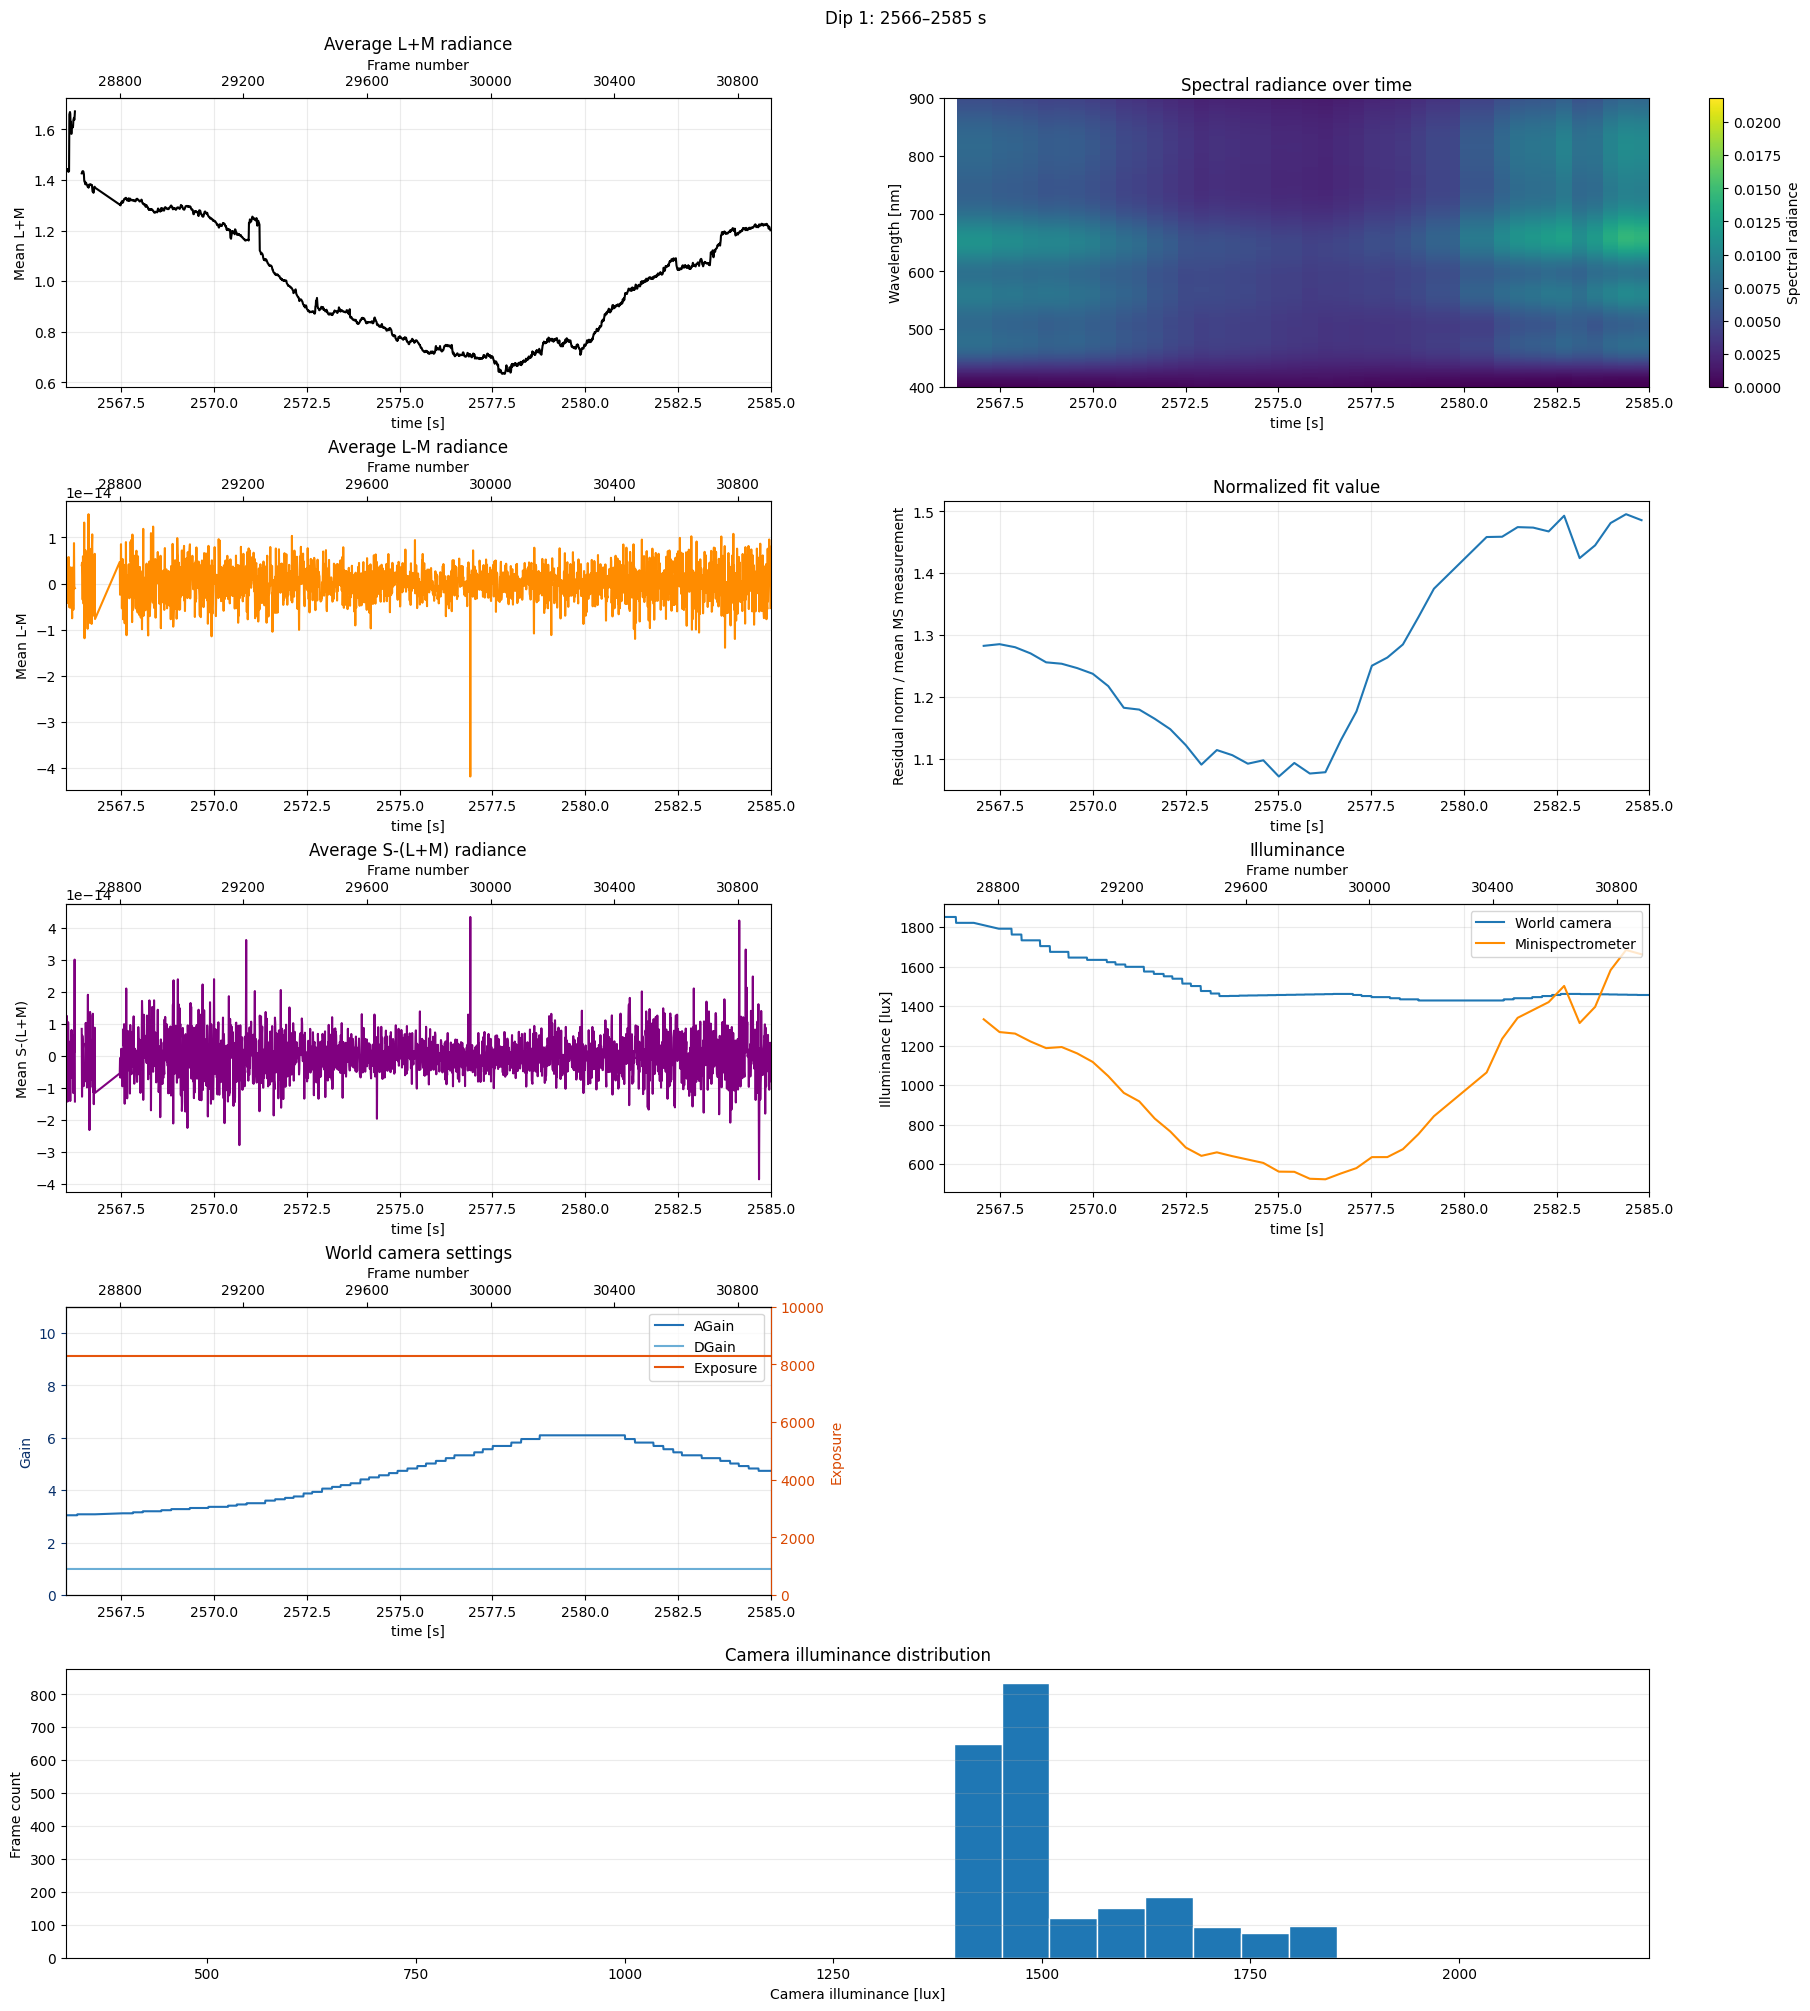

Plotting dip 2: 2624–2645 s


Loading world chunks:   0%|          | 0/47 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

... (39 outputs left out)

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/689 [00:00<?, ?it/s]

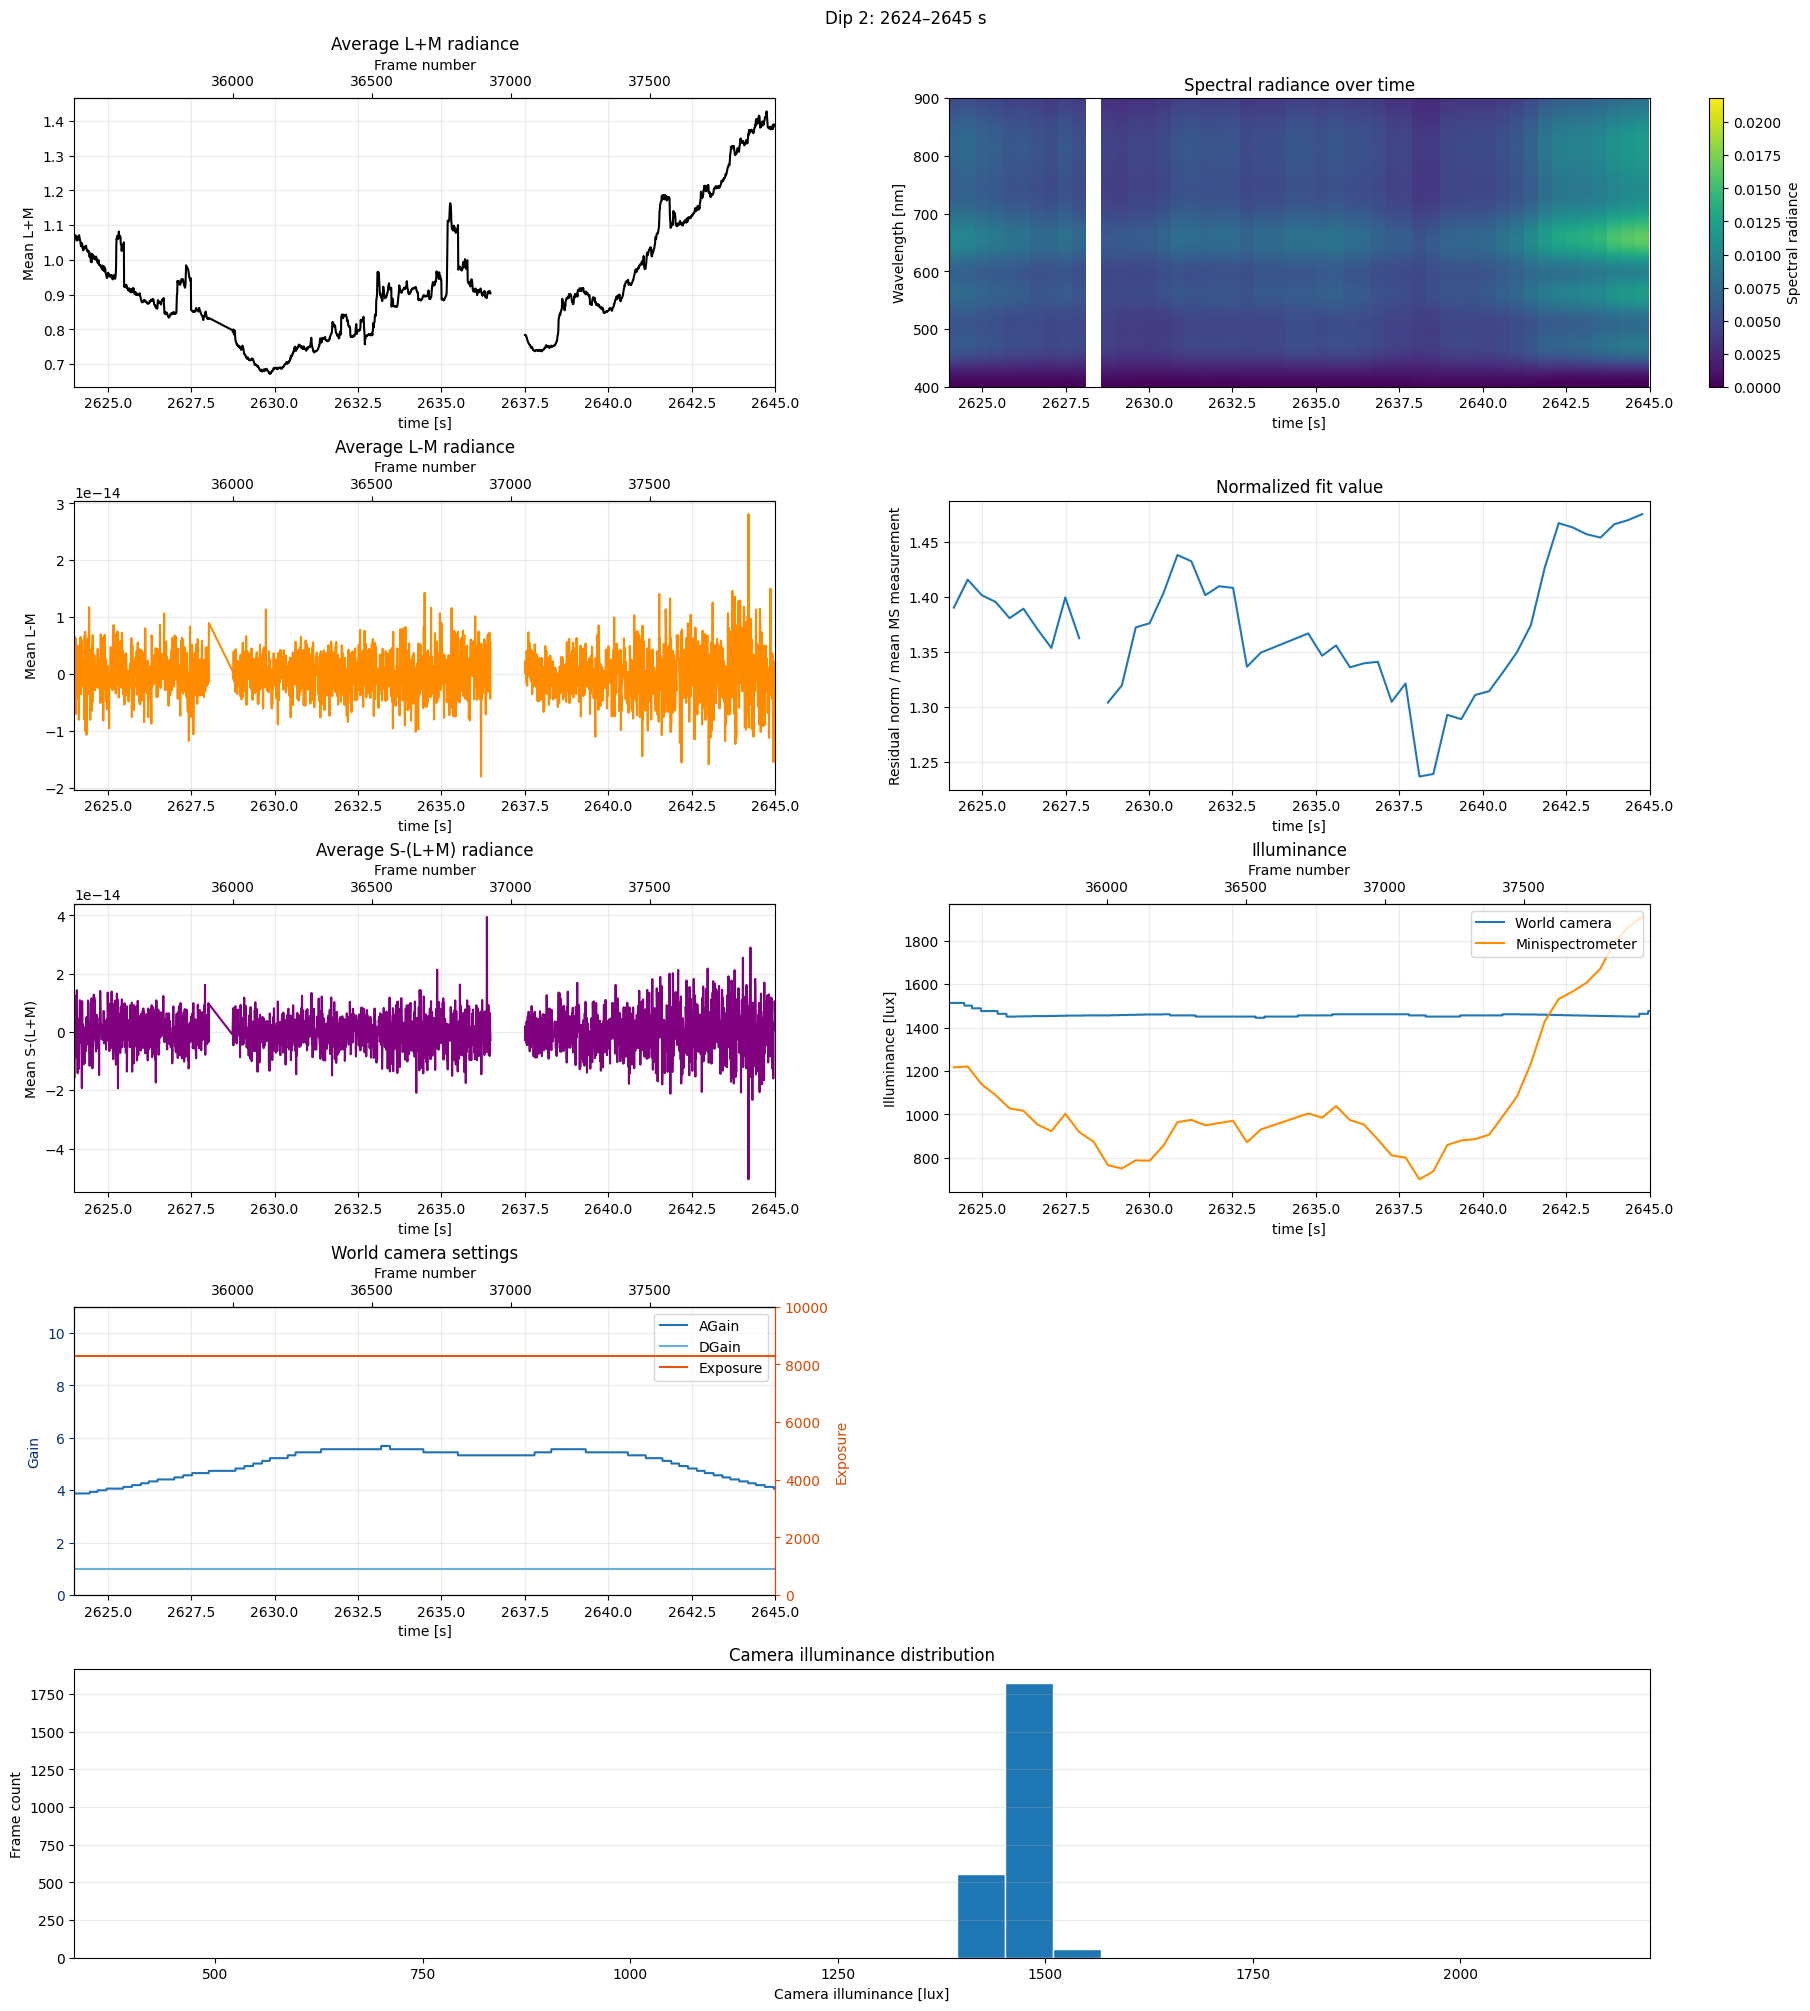

Plotting dip 3: 2665–2686 s


Loading world chunks:   0%|          | 0/47 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

... (39 outputs left out)

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/689 [00:00<?, ?it/s]

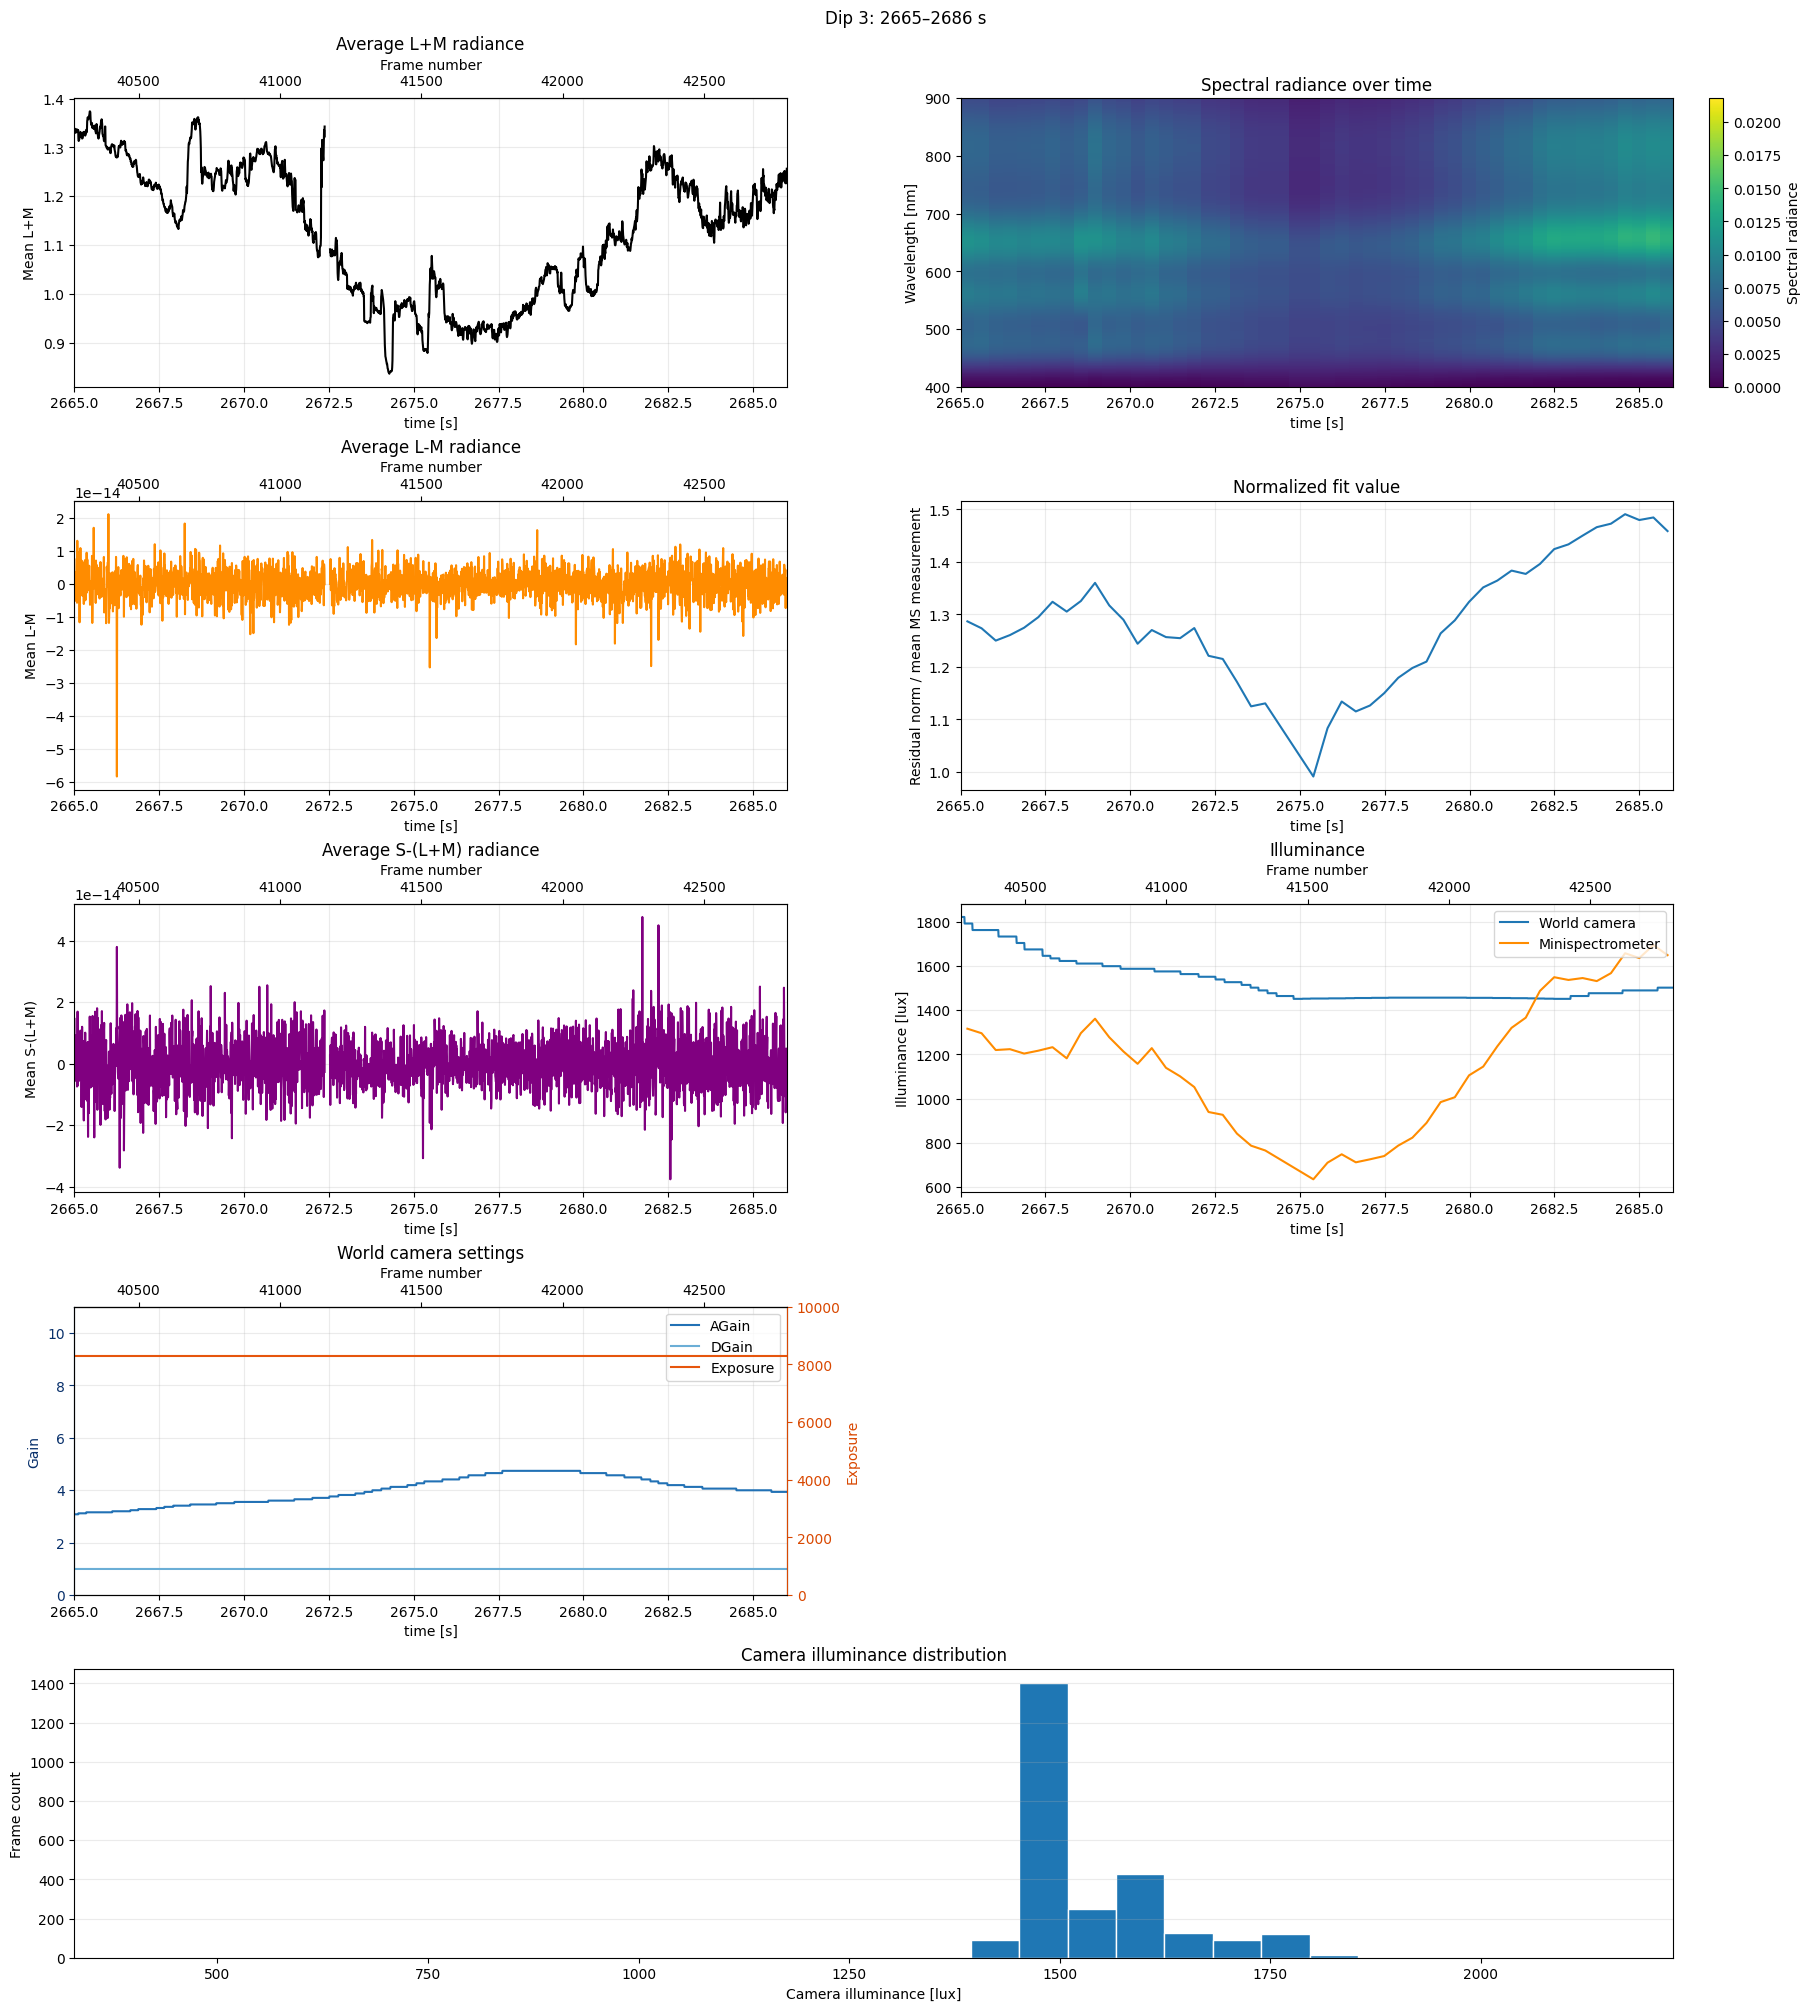

Plotting dip 4: 2708–2719 s


Loading world chunks:   0%|          | 0/47 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

... (39 outputs left out)

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/689 [00:00<?, ?it/s]

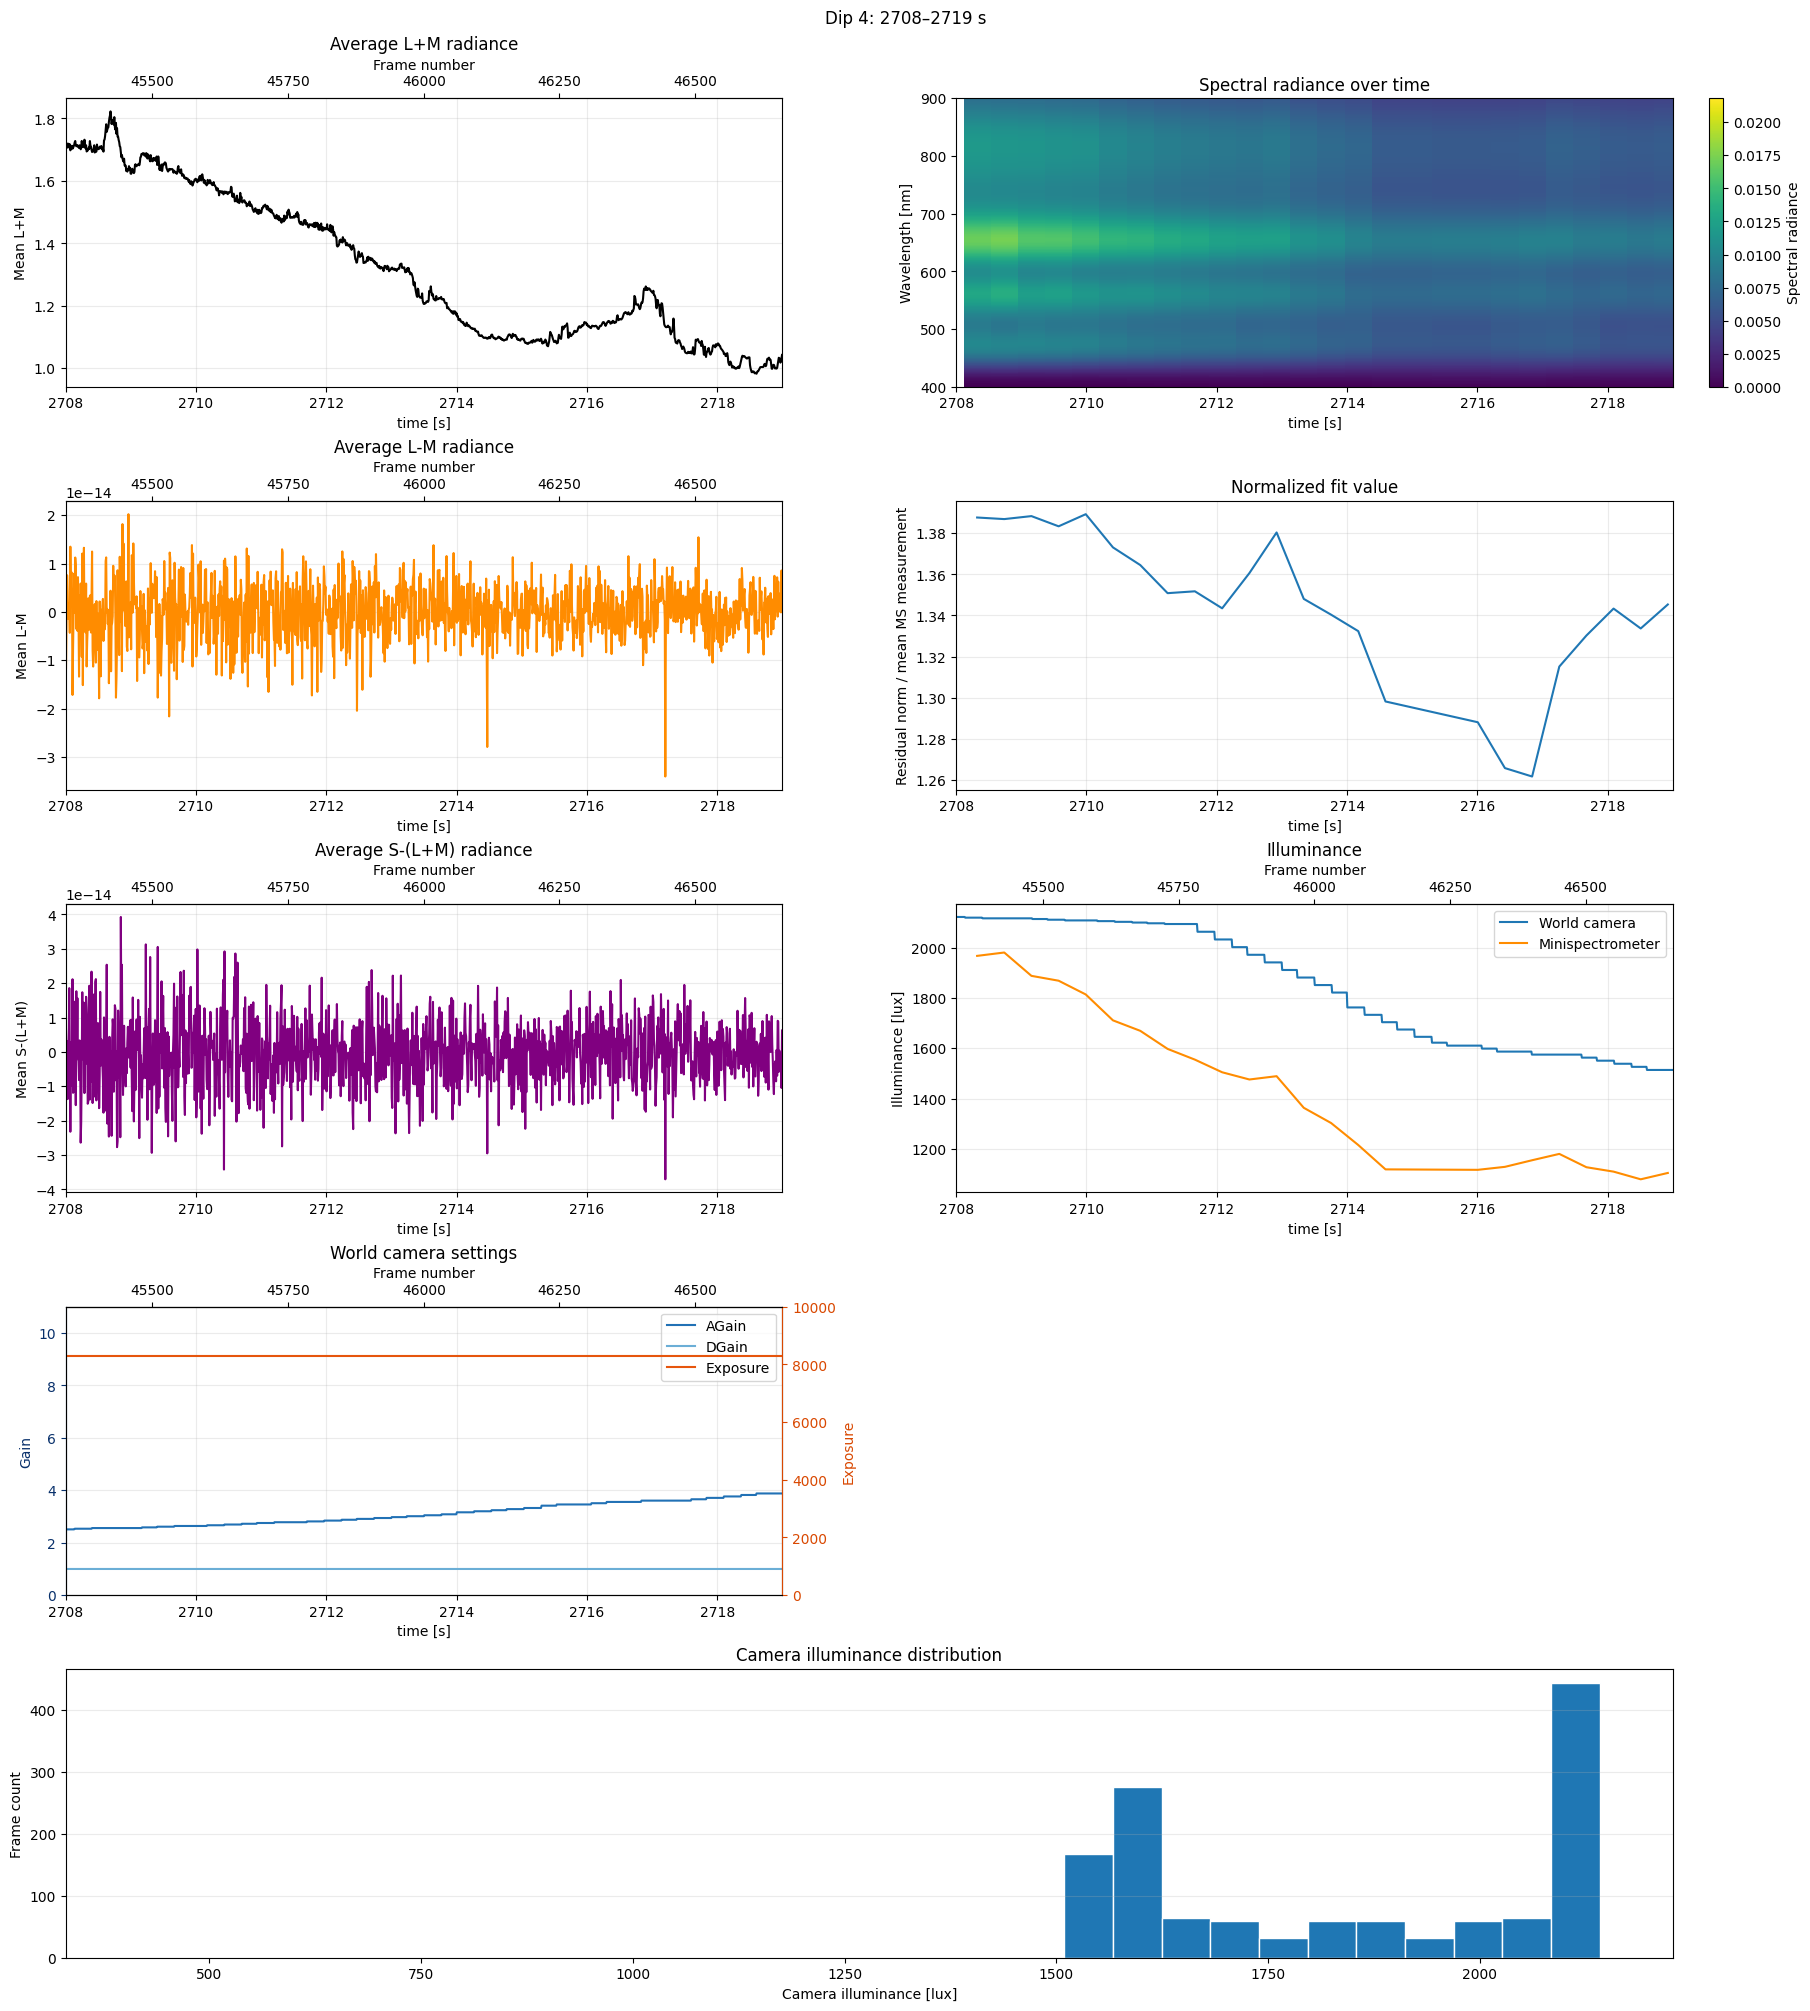

Finished plotting all four dips.


In [5]:
# Plot each illuminance dip from the full processed recording.
# The histogram counts only camera samples in each [start, end) interval.
import importlib
from IPython.display import display

importlib.reload(world_util)
importlib.reload(sensors_utility)

dip_starts: tuple[float, ...] = (2566., 2624., 2665., 2708.)
dip_ends: tuple[float, ...] = (2585., 2645., 2686., 2719.)

for dip_number, (start, end) in enumerate(zip(dip_starts, dip_ends), start=1):
    print(f"Plotting dip {dip_number}: {start:g}–{end:g} s", flush=True)
    dip_figure, dip_axes = sensors_utility.plot_processed_recording(
        hdf5_path.expanduser().parent.parent, verbose=True,
        plot_title=f"Dip {dip_number}: {start:g}–{end:g} s",
        time_range=(start, end),
    )
    display(dip_figure)
    plt.close(dip_figure)

print("Finished plotting all four dips.")